# Phase 9 — The final holdout test

**Goal.** One honest, untouched test, run once. The walk-forward results of Phases 6–8 were reused to choose models, so they are no longer fully out of sample. The holdout (January 2019 onward) was never reused: it was sealed by content hash on 2026-10-07 and opened once, on 2026-10-20, by `python -m src.holdout.build`, with every rule fixed beforehand.

**What ran.** Every rule was fixed in PREREGISTRATION Entry 13 before the holdout was opened.

| Book | What it is | Its reading is decided by | Role |
|---|---|---|---|
| **Primary** | the real-time screened factor book, inverse-volatility mix, M3 GJR-GARCH, inverse-variance timing, monthly, cap 1.5 | **(c)**: each holding year scaled to an equal risk budget (Entry 10); the unscaled (a) beside it | **the final test** |
| Best variant | Phase 7's family member with the largest development gain: M0, downside-volatility timing, shrunk mean-variance mix, weekly | (c), with (a) beside | secondary |
| ETF track | SPY alone (M2) and SPY + MTUM's market-hedged tilt (M3), after costs | (a) | tradeable secondary |
| Fixed book | Phase 6's market + momentum + BAB book, the primary's specification | (a) | information |

Every paper result is an upper bound: paper factors cannot be traded as built, and they carry no costs.

**How.** Each run is the development walk-forward continued on the joined panel. Each decision reads only data up to its own close, and the account carries its December 2018 position into January 2019.

**The answer in one line.** Every book reads **inconclusive**. The primary gains +0.09 Sharpe a year (p 0.31), against a minimum detectable effect of 0.45. Development had not won either, so by the plan's table the result is **consistent with Cederburg et al.**

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from src import holdout as ho
from src.config import PROCESSED_DIR, REPORTS_DIR
from src.holdout import setup

pd.set_option("display.float_format", "{:,.4f}".format, "display.max_columns", 40, "display.width", 220,
              "display.max_colwidth", None, "display.max_rows", 250)

BLUE, AMBER, PURPLE, TEAL, ROSE = "#2a78d6", "#eda100", "#4a3aa7", "#1a9e8f", "#c2456b"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
BOOKS = ["primary", "best", "spy", "etf", "fixed"]
COLOR = {"primary": BLUE, "best": AMBER, "spy": TEAL, "etf": ROSE, "fixed": PURPLE}
SHORT = {"primary": "Primary", "best": "Best variant", "spy": "SPY alone", "etf": "SPY + MTUM tilt", "fixed": "Fixed book (info)"}
CRISIS_NAME = {("primary", "frozen"): "Primary", ("best", "frozen"): "Best variant (weekly)", ("fixed", "frozen"): "Fixed book",
               ("spy", "frozen"): "SPY alone", ("etf", "frozen"): "SPY + MTUM tilt", ("mom", "frozen"): "Momentum: frozen rule",
               ("mom", "bsc"): "Momentum: B&SC", ("mkt", "bsc"): "Market: B&SC"}

# Everything below reads what `python -m src.holdout.build` wrote.
SUMMARY = pd.read_csv(REPORTS_DIR / "phase9_summary.csv", index_col=0)["value"]
K = pd.read_csv(REPORTS_DIR / "phase9_checks.csv")
SURV = pd.read_csv(REPORTS_DIR / "phase9_survivors.csv")
T = pd.read_csv(REPORTS_DIR / "phase9_results.csv")
YEARS = pd.read_csv(REPORTS_DIR / "phase9_years.csv")
PL = pd.read_csv(REPORTS_DIR / "phase9_placebo.csv")
Q = pd.read_csv(REPORTS_DIR / "phase9_crises.csv", parse_dates=["peak", "trough", "window_start", "window_end"], dtype={"episode": str})
V = pd.read_csv(REPORTS_DIR / "phase9_verdict.csv")
RUNS = pd.read_parquet(PROCESSED_DIR / "phase9_runs.parquet")
RUNS["month"] = pd.PeriodIndex(RUNS["month"], freq="M")
PATHS = pd.read_parquet(PROCESSED_DIR / "phase9_paths.parquet")
DRAWS = pd.read_parquet(PROCESSED_DIR / "phase9_placebo_draws.parquet")
DEC = T[T["decides"]].set_index("book")
print(f"{SUMMARY['mode']}: "
      f"primary {int(DEC.loc['primary', 'months'])} holdout months, gain {DEC.loc['primary', 'stat_gain']:+.3f} "
      f"under {DEC.loc['primary', 'statistic']}: {DEC.loc['primary', 'stat_reading']}")

final test: primary 91 holdout months, gain +0.088 under (c): inconclusive


## 1. What 92 months can and cannot tell

Lo's (2002) standard error of an annual Sharpe ratio of 0.5 over 92 months, step by step (the plan's worked example):
1. Monthly Sharpe: 0.5 / √12 ≈ 0.144.
2. Monthly standard error: √((1 + ½ · 0.144²) / 92) ≈ 0.105.
3. Annualized: 0.105 × √12 ≈ 0.36.

So the 95% interval is about 0.5 ± 0.71. Each Sharpe ratio in this report carries an error of that size (Section 5).

The test is on the **gain**, timed minus buy-and-hold. That gain is measured more precisely than either Sharpe ratio, because the two runs move together, but not by much. Its standard error here is 0.14–0.18, and its minimum detectable effect at 80% power is 0.35–0.45. So **the holdout cannot prove a small edge, but it can catch a large failure.**

In [2]:
ex = setup.lo_example(0.5, 92)
steps = pd.Series({"annual Sharpe ratio": ex["sharpe"], "months": ex["months"], "1. monthly Sharpe = 0.5 / √12": ex["monthly_sharpe"],
                   "2. standard error, monthly = √((1 + ½ SR²) / T)": ex["se_monthly"], "3. annualized (× √12)": ex["se_annual"],
                   "95% half-width (1.96 ×)": ex["half_width_95"]})
display(steps.to_frame("Lo (2002)").style.format("{:.3f}"))

,Lo (2002)
annual Sharpe ratio,0.500
months,92.000
1. monthly Sharpe = 0.5 / √12,0.144
"2. standard error, monthly = √((1 + ½ SR²) / T)",0.105
3. annualized (× √12),0.363
95% half-width (1.96 ×),0.712


## 2. The freeze and the one run

- **Frozen first.** The code, models, parameters and cutoffs were fixed in PREREGISTRATION Entry 13 before the holdout was opened. They are shown below.
- **Run once.** The holdout was opened once, on 2026-10-20, for the panel and the ETF table, and not again. The build now refuses to start once its results exist.
- **This notebook does not open the holdout.** It reads only what the build wrote.

In [3]:
display(pd.DataFrame({"value": ho.HOLDOUT_RULES}).astype(str))

,value
start,2019-01-01
data,"the sealed snapshot (data/holdout_lock.json), last day 2026-08-31; not refreshed"
paper_end,the last month in which every factor has a return on every trading day
etf_end,the last month in which SPY and MTUM have a return on every trading day
year_end,the last trading day of December; the data's last day is not a year-end
primary,"('M3', 'inv_var', 'inv_vol', 'monthly')"
best,"('M0', 'down_vol', 'shrunk_mv', 'weekly')"
decides,"{'primary': '(c)', 'best': '(c)', 'spy': '(a)', 'etf': '(a)', 'fixed': '(a)'}"
scoring,"calendar months from the daily ledger (src/robustness/ledger.py), at every frequency"
fixed_from,the recipe set at the last year-end before the holdout


## 3. Checks of the run

**Appending the holdout changed nothing before it.** On every development month, each run equals its Phase 7 run exactly:
- the primary: all 38 numeric columns of the engine's output, 276 months;
- the best variant (under Phase 7's scoring), SPY alone and SPY + MTUM.

The screen's verdicts and the recipe weights at every development year-end equal Phase 7's. So every holdout decision came from the same code and rules that produced the development results.

**Where the data end.**
- The paper books end in July 2026, because AQR's BAB file ends on 31 July 2026. That gives 91 scored months.
- The ETF track ends in August 2026, giving 92 months.
- No year-end screen came up empty, so no holdout month was left in cash.

In [4]:
display(K.style.format({"max_abs_diff": "{:.1e}", "months": "{:.0f}", "missing_months": "{:.0f}"}, na_rep=""))
s = SUMMARY[[k for k in SUMMARY.index if k.startswith(("months_", "first_", "last_")) or k in ("panel_last", "paper_end", "etf_end")]]
display(s.to_frame("value"))

,book,what,months,first,last,max_abs_diff,missing_months
0,primary,"every numeric column of the run (38), against Phase 7",276,1984-01,2018-12,0.0e+00,0
1,best,"monthly excess, bench_excess and size, against Phase 7",276,1984-01,2018-11,0.0e+00,0
2,spy,"monthly excess, bench_excess and size, against Phase 7",263,1997-02,2018-12,0.0e+00,0
3,etf,"monthly excess, bench_excess and size, against Phase 7",20,2017-05,2018-12,0.0e+00,0
4,screen,"factors passing filters 1, 3 and 6 with 120 months, at every year-end before the holdout",651,,,0.0e+00,0
5,recipes,mix weights at every year-end before the holdout (CSV precision),100,,,8.3e-17,0


,value
panel_last,2026-08-31
paper_end,2026-07-31
etf_end,2026-08-31
months_primary,91
months_best,91
months_spy,92
months_etf,92
months_fixed,91
first_primary,2019-01
first_best,2019-01


## 4. The holdout's book: the survivors at each year-end (Entry 10)

The real-time screen admitted **market, momentum and BAB at every year-end from 2018 to 2025**. It also admitted **profitability for 2020 and 2022**, from the 2019 and 2021 year-ends. No pair was close enough to be dropped as a duplicate, and no year was empty.

In the other six years the primary holds exactly Phase 6's fixed book, so the two differ only in 2020 and 2022. The second table shows the filter statistics behind the screen. Level φ and the spanning α's t-statistic barely move, because their windows are expanding and already 60–100 years long.

In [5]:
cols = ["asof", "held_in", "survivors", "dropped"] + [c for c in SURV.columns if c.startswith(("inv_vol_", "shrunk_mv_"))]
s = SURV[cols].set_index("held_in")
display(s.style.format({c: "{:.3f}" for c in cols if c.startswith(("inv_vol_", "shrunk_mv_"))}, na_rep="–"))
phi = SURV.set_index("held_in")[[c for c in SURV.columns if c.endswith(("_phi", "_t_alpha"))]]
display(phi.T.style.format("{:.3f}"))

,asof,survivors,dropped,inv_vol_mkt,inv_vol_mom,inv_vol_bab,inv_vol_sigma_hat,shrunk_mv_mkt,shrunk_mv_mom,shrunk_mv_bab,shrunk_mv_sigma_hat,inv_vol_rmw,shrunk_mv_rmw
held_in,,,,,,,,,,,,,
2019,2018-12-31,mkt mom bab,–,0.263,0.312,0.425,0.072,0.322,0.167,0.511,0.065,–,–
2020,2019-12-31,mkt mom rmw bab,–,0.138,0.190,0.289,0.042,0.255,0.125,0.443,0.046,0.383,0.177
2021,2020-12-31,mkt mom bab,–,0.258,0.306,0.437,0.090,0.318,0.167,0.515,0.087,–,–
2022,2021-12-31,mkt mom rmw bab,–,0.163,0.175,0.250,0.055,0.255,0.125,0.374,0.067,0.412,0.246
2023,2022-12-30,mkt mom bab,–,0.273,0.292,0.435,0.097,0.325,0.167,0.508,0.093,–,–
2024,2023-12-29,mkt mom bab,–,0.277,0.290,0.434,0.097,0.348,0.167,0.485,0.094,–,–
2025,2024-12-31,mkt mom bab,–,0.278,0.288,0.435,0.098,0.390,0.167,0.443,0.096,–,–
2026,2025-12-31,mkt mom bab,–,0.277,0.290,0.433,0.098,0.448,0.167,0.385,0.100,–,–


held_in,2019,2020,2021,2022,2023,2024,2025,2026
mkt_phi,0.621,0.620,0.552,0.552,0.553,0.553,0.554,0.549
mkt_t_alpha,3.224,3.108,2.997,2.964,3.047,3.014,3.037,3.054
smb_phi,0.595,0.595,0.589,0.589,0.589,0.589,0.588,0.588
smb_t_alpha,-0.735,-0.745,-0.904,-0.891,-0.852,-0.863,-0.788,-0.768
hml_phi,0.726,0.725,0.725,0.721,0.724,0.724,0.722,0.722
hml_t_alpha,1.616,1.634,1.756,1.691,1.621,1.676,1.703,1.673
mom_phi,0.535,0.535,0.525,0.521,0.523,0.523,0.523,0.523
mom_t_alpha,7.612,7.601,7.739,7.779,7.739,7.812,7.781,7.772
rmw_phi,0.761,0.760,0.762,0.765,0.758,0.756,0.756,0.756
rmw_t_alpha,3.016,3.014,2.975,2.880,2.870,2.891,2.885,2.987


## 5. The one-shot numbers

Each book is tested with Entry 3's statistic: the Sharpe gain over buy-and-hold, by Ledoit-Wolf with a Newey-West covariance, one-sided at 5%. The row in bold is the statistic that decides the book's reading.

In [6]:
cols = {"name": "book", "statistic": "statistic", "months": "months", "stat_sharpe": "Sharpe timed", "stat_bh_sharpe": "Sharpe B&H",
        "stat_gain": "gain", "stat_se": "se", "stat_p": "p (one-sided)", "stat_lower": "95% lower", "stat_upper": "95% upper",
        "stat_mde": "MDE (80%)", "stat_reading": "reading", "decides": "decides"}
t = T[list(cols)].rename(columns=cols)
fmt = {c: "{:.3f}" for c in ["Sharpe timed", "Sharpe B&H", "se", "95% lower", "95% upper", "MDE (80%)"]}
display(t.style.format({**fmt, "gain": "{:+.3f}", "p (one-sided)": "{:.4f}", "months": "{:.0f}"}).apply(
    lambda r: ["font-weight: bold" if r["decides"] else "" for _ in r], axis=1))

,book,statistic,months,Sharpe timed,Sharpe B&H,gain,se,p (one-sided),95% lower,95% upper,MDE (80%),reading,decides
0,"Primary (screened book, M3)",(c),91,0.744,0.656,+0.088,0.183,0.3145,-0.212,0.388,0.454,inconclusive,True
1,"Primary (screened book, M3)",(a),91,0.897,0.855,+0.041,0.182,0.4101,-0.257,0.340,0.451,inconclusive,False
2,"Best variant (M0, downside vol, shrunk MV, weekly)",(c),91,0.651,0.765,-0.114,0.180,0.7365,-0.411,0.183,0.449,inconclusive,True
3,"Best variant (M0, downside vol, shrunk MV, weekly)",(a),91,0.844,0.959,-0.115,0.139,0.7960,-0.345,0.114,0.347,inconclusive,False
4,ETF track: SPY alone (M2),(a),92,0.790,0.891,-0.102,0.169,0.7262,-0.379,0.176,0.420,inconclusive,True
5,ETF track: SPY + MTUM tilt (M3),(a),92,0.482,0.468,+0.015,0.179,0.4666,-0.279,0.309,0.444,inconclusive,True
6,"Phase 6's fixed book (M3, information)",(a),91,0.857,0.777,+0.080,0.170,0.3193,-0.200,0.360,0.424,inconclusive,True


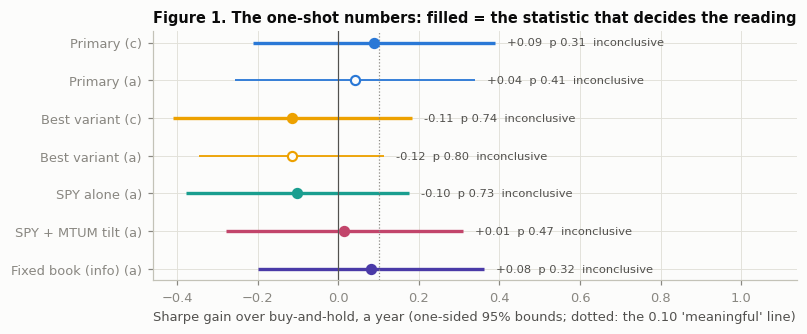

In [7]:
# Figure 1: each book's Sharpe gain with its one-sided 95% bounds, under the statistic that decides it (filled) and (a) (open)
fig, ax = plt.subplots(figsize=(7.4, 3.1))
rows = [(b, s) for b in BOOKS for s in T.loc[T["book"] == b, "statistic"]]
for i, (b, s) in enumerate(rows):
    r = T[(T["book"] == b) & (T["statistic"] == s)].iloc[0]
    y = len(rows) - 1 - i
    ax.plot([r["stat_lower"], r["stat_upper"]], [y, y], color=COLOR[b], lw=2.2 if r["decides"] else 1.2, solid_capstyle="butt")
    ax.scatter(r["stat_gain"], y, s=36, color=COLOR[b] if r["decides"] else SURFACE, edgecolor=COLOR[b], zorder=3, lw=1.4)
    ax.text(r["stat_upper"] + 0.03, y, f"{r['stat_gain']:+.2f}  p {r['stat_p']:.2f}  {r['stat_reading']}", va="center", fontsize=7.5, color=INK2)
ax.set_yticks(range(len(rows)), [f"{SHORT[b]} {s}" for b, s in rows][::-1])
ax.axvline(0, color=INK2, lw=0.8)
ax.axvline(0.10, color=MUTED, lw=0.8, ls=":")
ax.set_xlabel("Sharpe gain over buy-and-hold, a year (one-sided 95% bounds; dotted: the 0.10 'meaningful' line)")
lo, hi = T["stat_lower"].min(), T["stat_upper"].max()
ax.set_xlim(lo - 0.05, hi + 0.75)
ax.set_title("Figure 1. The one-shot numbers: filled = the statistic that decides the reading")
fig.tight_layout()

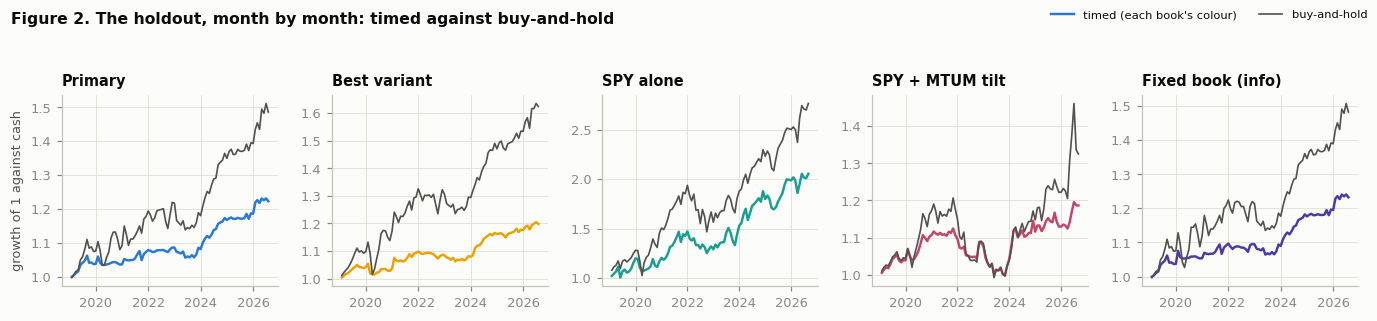

In [8]:
# Figure 2: growth against cash over the holdout, timed and buy-and-hold, each book (unscaled monthly excess returns)
fig, axes = plt.subplots(1, 5, figsize=(12.5, 2.9), sharey=False)
for ax, b in zip(axes, BOOKS):
    d = RUNS[(RUNS["book"] == b) & RUNS["holdout"]].set_index("month")
    t = d.index.to_timestamp(how="end")
    for col, c, lw in (("excess", COLOR[b], 1.6), ("bench_excess", INK2, 1.1)):
        g = (1 + d[col]).cumprod()
        ax.plot(t, g, color=c, lw=lw)
    ax.set_title(SHORT[b])
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_ylabel("growth of 1 against cash")
fig.legend(handles=[Line2D([], [], color=BLUE, lw=1.6, label="timed (each book's colour)"), Line2D([], [], color=INK2, lw=1.1, label="buy-and-hold")],
           loc="upper right", ncol=2, fontsize=7.5)
fig.suptitle("Figure 2. The holdout, month by month: timed against buy-and-hold", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))

**Reading.**

- **The final test is inconclusive.** Under (c), the primary's Sharpe ratio is 0.74 against buy-and-hold's 0.66:
  - gain **+0.088**, standard error 0.18, one-sided p **0.31**;
  - one-sided 95% bounds −0.21 to +0.39;
  - minimum detectable effect 0.45.

  The unscaled (a) gives +0.041 (p 0.41). The gain is a fifth of what the test could detect.
- **Every other book is inconclusive too:**

  | Book | Development gain | Holdout gain | p |
  |---|---|---|---|
  | Primary, (c) / (a) | +0.214 / +0.013 | +0.088 / +0.041 | 0.31 / 0.41 |
  | Best variant (c) | +0.234 (on (a)) | −0.114 | 0.74 |
  | SPY alone | +0.165 | −0.102 | 0.73 |
  | SPY + MTUM tilt | +0.088 (20 months) | +0.015 | 0.47 |
  | Fixed book (information) | +0.355 | +0.080 | 0.32 |

- **No large failure.** No book reads "no meaningful edge", which would need a loss of about 0.2 or more. The two negative gains have upper bounds near +0.18.
- **Each holdout gain sits below its development gain** under the same statistic. The one exception is the primary under (a), whose development gain had been held near zero by 1984.
  - The family's best variant fell furthest, from first of 192 to below the primary. Picking the best of many development variants did not carry over, as Phase 7's deflated Sharpe ratio (0.67) had warned.
  - Phase 6's fixed book kept about a quarter of its development edge: +0.08 against +0.355.
- **The ETF track, the tradeable version, did not help.** SPY timed alone lost 0.10 Sharpe after costs, most of it in 2020 (Section 6). The SPY + MTUM tilt was flat.

### 5a. Everything else Entry 6 reports, on the holdout months (unscaled)

Information beside the readings: the volatilities, size, CER, drawdowns, costs, the combination test and Lo's errors. The placebo is read for the primary only.

In [9]:
# Every metric of Entry 6, unscaled, on the holdout months
m = T[T["statistic"] == "(a)"].set_index("book")
rows = {"months": ("months", "{:.0f}"), "volatility: timed": ("volatility", "{:.2%}"), "volatility: buy-and-hold": ("bh_volatility", "{:.2%}"),
        "mean excess, a year: timed": ("mean", "{:+.2%}"), "mean excess: buy-and-hold": ("bh_mean", "{:+.2%}"),
        "mean size": ("mean_size", "{:.2f}"), "share of months capped": ("share_capped", "{:.0%}"),
        "CER (γ = 5): timed": ("cer", "{:+.2%}"), "CER: buy-and-hold": ("bh_cer", "{:+.2%}"), "CER gain": ("cer_gain", "{:+.2%}"), "CER test p": ("cer_p", "{:.3f}"),
        "Sortino: timed": ("sortino", "{:.2f}"), "Sortino: buy-and-hold": ("bh_sortino", "{:.2f}"),
        "max drawdown: timed": ("max_drawdown", "{:.1%}"), "max drawdown: buy-and-hold": ("bh_max_drawdown", "{:.1%}"),
        "turnover a year": ("turnover_a_year", "{:.1f}"), "break-even κ, one-way": ("break_even", "{:.2%}"),
        "spanning α, a year": ("alpha", "{:+.2%}"), "α t-stat (White)": ("t_alpha", "{:.2f}"),
        "combination: months": ("comb_months", "{:.0f}"), "combination: CER gain": ("comb_gain", "{:+.2%}"), "combination: p": ("comb_p", "{:.3f}"),
        "Lo SE of Sharpe: timed": ("lo_se", "{:.3f}"), "Lo SE of Sharpe: buy-and-hold": ("bh_lo_se", "{:.3f}")}
out = pd.DataFrame({SHORT[b]: [(f.format(m.loc[b, c]) if pd.notna(m.loc[b, c]) else "–") for c, f in rows.values()] for b in BOOKS}, index=list(rows))
display(out)
p = PL.iloc[0]
print(f"Placebo (information): the primary's real spanning α ({p['alpha']:+.2%}) beats {p['alpha_share']:.1%} of 1,000 shuffled forecasts "
      f"({'passes' if p['pass'] else 'fails'} the 95% bar); its real Sharpe gain beats {p['gain_share']:.1%} of theirs.")

,Primary,Best variant,SPY alone,SPY + MTUM tilt,Fixed book (info)
months,91,91,92,92,91
volatility: timed,3.01%,2.88%,13.00%,4.86%,3.28%
volatility: buy-and-hold,6.35%,6.93%,16.48%,8.66%,7.01%
"mean excess, a year: timed",+2.70%,+2.43%,+10.26%,+2.35%,+2.81%
mean excess: buy-and-hold,+5.43%,+6.65%,+14.69%,+4.05%,+5.45%
mean size,0.47,0.41,0.98,0.69,0.49
share of months capped,0%,1%,21%,0%,0%
CER (γ = 5): timed,+2.47%,+2.22%,+6.04%,+1.76%,+2.54%
CER: buy-and-hold,+4.42%,+5.45%,+7.90%,+2.17%,+4.22%
CER gain,-1.96%,-3.22%,-1.86%,-0.42%,-1.68%


Placebo (information): the primary's real spanning α (+0.63%) beats 69.5% of 1,000 shuffled forecasts (fails the 95% bar); its real Sharpe gain beats 77.2% of theirs.


In [10]:
y = YEARS.copy()
cols = ["book", "year", "assets", "months", "timed", "bh", "timed_vol", "bh_vol", "mean_size", "sigma_hat"]
display(y[cols].set_index(["book", "year"]).style.format({"timed": "{:+.1%}", "bh": "{:+.1%}", "timed_vol": "{:.1%}", "bh_vol": "{:.1%}",
                                                         "mean_size": "{:.2f}", "sigma_hat": "{:.1%}", "months": "{:.0f}"}, na_rep="–"))

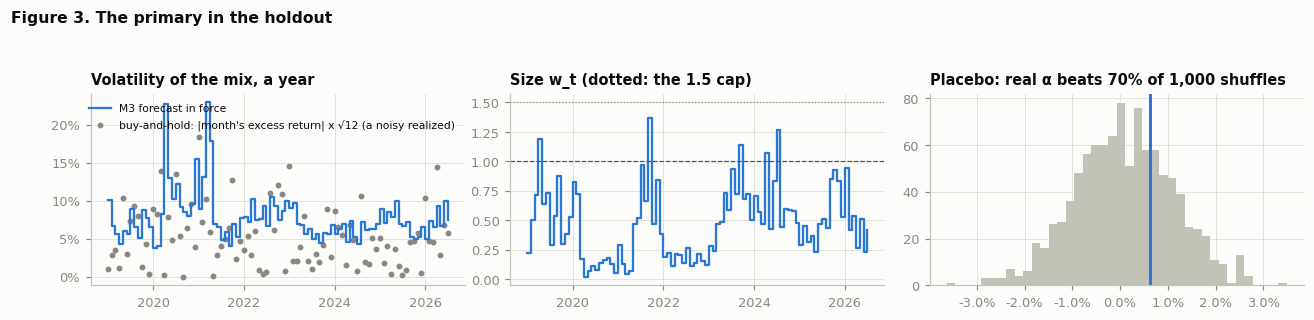

In [11]:
# Figure 3: the primary through the holdout: the forecast in force (as a volatility), the size, and the placebo
res = pd.read_parquet(PROCESSED_DIR / "phase9_primary.parquet")
res["month"] = pd.PeriodIndex(res["month"], freq="M")
res = res[res["month"] >= pd.Period("2019-01", "M")].set_index("month")
t = res.index.to_timestamp()
d = RUNS[(RUNS["book"] == "primary") & RUNS["holdout"]].set_index("month")
fig, axes = plt.subplots(1, 3, figsize=(12, 2.9))
axes[0].plot(t, np.sqrt(res["forecast"] * 252 / 22), color=BLUE, drawstyle="steps-post", label="M3 forecast in force")
axes[0].scatter(t, d["bench_excess"].abs() * np.sqrt(12), s=8, color=MUTED, label="buy-and-hold: |month's excess return| x √12 (a noisy realized)")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].set_title("Volatility of the mix, a year")
axes[0].legend(fontsize=7)
axes[1].plot(t, res["size"], color=BLUE, drawstyle="steps-post")
axes[1].axhline(1.0, color=INK2, lw=0.8, ls="--"); axes[1].axhline(1.5, color=MUTED, lw=0.8, ls=":")
axes[1].set_title("Size w_t (dotted: the 1.5 cap)")
from src.engine import evaluation as ev
b = d["bench_excess"]
al = np.array([ev.alpha(pd.Series(DRAWS.loc[i].to_numpy(), index=b.index), b) for i in DRAWS.index])     # each shuffle's α, holdout months
axes[2].hist(al, bins=40, color=AXIS)
axes[2].axvline(PL.iloc[0]["alpha"], color=BLUE, lw=2)
axes[2].xaxis.set_major_formatter(lambda x, _: f"{x:.1%}")
axes[2].set_title(f"Placebo: real α beats {PL.iloc[0]['alpha_share']:.0%} of 1,000 shuffles")
for ax in axes[:2]:
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Figure 3. The primary in the holdout", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))

**Reading.**

- **Timing cut risk sharply, in every book:**

  | Book | Volatility, timed / buy-and-hold | Maximum drawdown, timed / buy-and-hold |
  |---|---|---|
  | Primary | 3.0% / 6.4% | −2.8% / −6.8% |
  | SPY alone | 13.0% / 16.5% | −15.0% / −24.3% |

- **But it held too little to earn as much.** The primary's mean size was **0.47**, and the 1.5 cap never bound.
  - In 2019–2026 the mix's forecast volatility averaged 7.8% a year, against 5.3% in 1997–2018. c_t is set on that long, calmer history, so the rule de-levered.
  - 2020 and 2022, the years that also held profitability, had sizes of only 0.22 and 0.17.
  - CER follows size at these volatilities (Entry 3): 2.5% timed against 4.4% buy-and-hold. The CER test's one-sided p for a gain is 0.98.
- **Little left after costs.** The primary's break-even cost is 5 bp one-way. SPY alone, which does pay costs, has no gain to break even on.
- **The combination test** (Cederburg et al.'s real-time investor, trained on every earlier scored month) adds nothing: −0.03 points of CER for the primary (p 0.52), and negative for the best variant and SPY.
- **The placebo fails** (information). The primary's real spanning α, +0.63% a year (t 0.9), beats 69.5% of 1,000 shuffled forecasts, against the 95% bar. In development it beat 86.3%.
- **Lo's standard errors** of every Sharpe ratio here are 0.36–0.37, as the worked example said. Each timed and buy-and-hold Sharpe ratio is known only to about ±0.7.

## 6. Crisis case studies: 2020 and 2022

**Why.** Averages hide the months that matter most. A strategy that cuts risk after the crash and misses the recovery can look fine on average and still be painful to hold.

**The episodes** (Entry 13, Section 6, fixed before the holdout was opened):
- **The trough:** the market's lowest total-return close in the year.
- **The peak:** its highest close from 1 January 2020, or from 1 January 2021 for 2022, up to the trough.
- **The window:** 6 months before the peak to 12 months after the trough.

The market fell 34.2% from 19 February to 23 March 2020, and 25.6% from 8 November 2021 to 14 October 2022.

**The three questions** are Phase 8's (Entry 8):
1. Did it cut risk before or after buy-and-hold's five worst days?
2. Did it miss the rebound?
3. How much did the cap and costs matter?

Every holdout book, momentum alone and the market alone are shown.

**The panels.** Each column is one run, with four rows:
- the price of buy-and-hold (dots: its five worst days);
- the forecast in force as an annual volatility (for the best variant, its downside forecast) beside the realized 22-day volatility;
- the size;
- growth against cash, timed against buy-and-hold.

In [12]:
s = Q.drop_duplicates("episode")[["episode", "peak", "trough", "window_start", "window_end", "market_fall"]].set_index("episode")
s["shown"] = [", ".join(dict.fromkeys(CRISIS_NAME[(b, v)] for b, v in zip(Q.loc[Q["episode"] == e, "book"], Q.loc[Q["episode"] == e, "version"]))) for e in s.index]
display(s.style.format({"market_fall": "{:.1%}", "peak": "{:%d %b %Y}", "trough": "{:%d %b %Y}", "window_start": "{:%d %b %Y}", "window_end": "{:%d %b %Y}"}))


def crisis_panel(episode, number, runs_):
    """The plan's four rows for one episode, day by day: price, σ̂, size, growth against cash, for each run."""
    q = Q[Q["episode"] == episode]
    peak, trough, start, end = q["peak"].iloc[0], q["trough"].iloc[0], q["window_start"].iloc[0], q["window_end"].iloc[0]
    fig, axes = plt.subplots(4, len(runs_), figsize=(12.5, 7.6), sharex=True, squeeze=False,
                             gridspec_kw={"height_ratios": [1.1, 1, 0.8, 1.1]})
    for j, (book, version) in enumerate(runs_):
        d = PATHS[(PATHS["episode"] == episode) & (PATHS["book"] == book) & (PATHS["version"] == version)].set_index("date")
        realized = np.sqrt((d["bench_ret"] ** 2).rolling(22).sum() * 252 / 22).loc[start:]
        d = d.loc[start:]
        c = COLOR.get(book, AMBER if version == "bsc" else BLUE)
        row = q[(q["book"] == book) & (q["version"] == version)].iloc[0]
        worst = pd.to_datetime(row["worst_days"].split(", "))
        bh = d["bench_value"] / d["bench_value"].iloc[0]
        axes[0, j].plot(bh.index, bh, color=INK2, lw=1.2)
        axes[0, j].scatter(worst, bh.loc[worst], s=16, color=INK, zorder=3)
        axes[0, j].set_title(CRISIS_NAME[(book, version)])
        axes[1, j].plot(realized.index, realized, color=MUTED, lw=0.8)
        axes[1, j].plot(d.index, np.sqrt(d["forecast"] * 252 / d["horizon"]), color=c, lw=1.4, drawstyle="steps-post")
        axes[1, j].yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
        axes[2, j].plot(d.index, d["size"], color=c, lw=1.4, drawstyle="steps-post")
        axes[2, j].axhline(1.0, color=INK2, lw=0.8, ls="--")
        g = d["value"] / d["value"].iloc[0]
        axes[3, j].plot(g.index, g, color=c, lw=1.6)
        axes[3, j].plot(bh.index, bh, color=INK2, lw=1.2)
        for i in range(4):
            axes[i, j].axvspan(peak, trough, color=AXIS, alpha=0.25, lw=0)
    axes[0, 0].set_ylabel("price: buy-and-hold\n(window start = 1)")
    axes[1, 0].set_ylabel("volatility, a year")
    axes[2, 0].set_ylabel("size w_t")
    axes[3, 0].set_ylabel("growth against cash\n(window start = 1)")
    for ax in axes[3]:
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=5))
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    handles = [Line2D([], [], color=BLUE, lw=1.6, label="timed (forecast in force, size, growth)"), Line2D([], [], color=INK2, lw=1.2, label="buy-and-hold"),
               Line2D([], [], color=MUTED, lw=0.8, label="realized 22-day volatility"),
               Line2D([], [], color=INK, marker="o", lw=0, ms=4, label="buy-and-hold's 5 worst days")]
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=4, fontsize=7.5)
    fig.suptitle(f"Figure {number}. {episode}: market peak {peak:%d %b %Y}, trough {trough:%d %b %Y} (shaded)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.93))


def crisis_table(episode):
    """The three questions for each run in the episode."""
    q = Q[Q["episode"] == episode].copy()
    q["run"] = [CRISIS_NAME[(b, v)] for b, v in zip(q["book"], q["version"])]
    cols = {"lead_size": "1. size, 6 months before", "peak_size": "1. size at the peak", "worst_size": "1. size on the 5 worst days",
            "worst_timed": "1. loss on them: timed", "worst_bench": "1. loss on them: buy-and-hold", "worst_share": "1. share of the loss",
            "fall_timed": "2. fall: timed", "fall_bench": "2. fall: buy-and-hold", "fall_size": "2. size in the fall",
            "rebound_timed": "2. rebound: timed", "rebound_bench": "2. rebound: buy-and-hold", "rebound_size": "2. size in the rebound",
            "window: as run": "3. window: as run", "window: no cap": "3. no cap", "window: cap 1.0": "3. cap 1.0",
            "window: cap 1.5": "3. cap 1.5", "window: 30 bp": "3. at 30 bp", "window_bench": "3. window: buy-and-hold"}
    t = q.set_index("run")[[c for c in cols if c in q]].rename(columns=cols).T
    size = [k for k in t.index if "size" in k or "share" in k]
    pct = [k for k in t.index if k not in size]
    return t.style.format("{:+.1%}", subset=pd.IndexSlice[pct, :], na_rep="–").format("{:.2f}", subset=pd.IndexSlice[size, :], na_rep="–")

,peak,trough,window_start,window_end,market_fall,shown
episode,,,,,,
2020,19 Feb 2020,23 Mar 2020,19 Aug 2019,23 Mar 2021,-34.2%,"Primary, Best variant (weekly), Fixed book, SPY alone, SPY + MTUM tilt, Momentum: B&SC, Market: B&SC, Momentum: frozen rule"
2022,08 Nov 2021,14 Oct 2022,08 May 2021,14 Oct 2023,-25.6%,"Primary, Best variant (weekly), Fixed book, SPY alone, SPY + MTUM tilt, Momentum: B&SC, Market: B&SC, Momentum: frozen rule"


### 6a. 2020: a crash out of calm, then a fast rebound

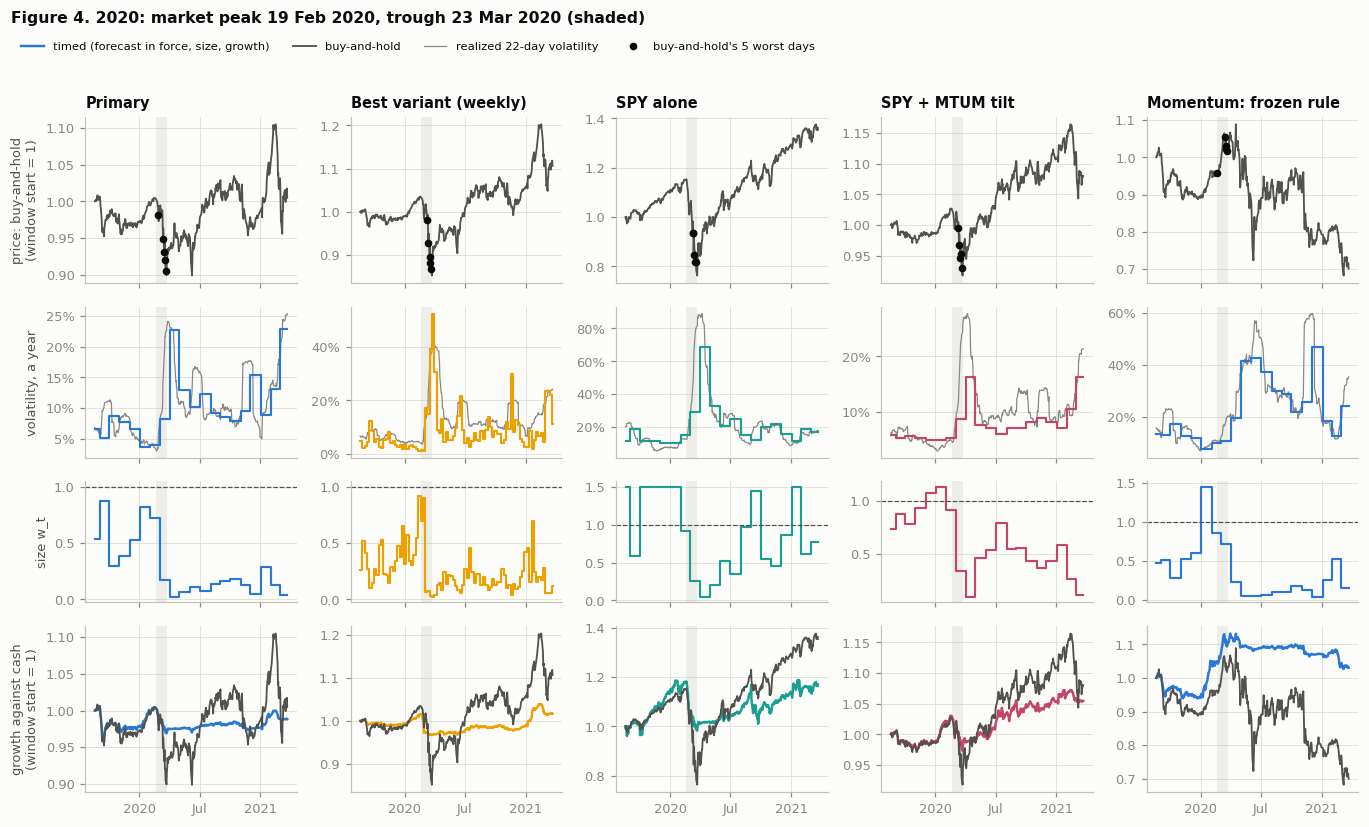

In [13]:
crisis_panel("2020", 4, [k for k in [("primary", "frozen"), ("best", "frozen"), ("spy", "frozen"), ("etf", "frozen"), ("mom", "frozen")] if ((Q["episode"] == "2020") & (Q["book"] == k[0]) & (Q["version"] == k[1])).any()])

In [14]:
crisis_table("2020")

run,Primary,Best variant (weekly),Fixed book,SPY alone,SPY + MTUM tilt,Momentum: B&SC,Market: B&SC,Momentum: frozen rule
"1. size, 6 months before",0.59,0.37,0.56,1.30,0.94,0.84,0.89,0.67
1. size at the peak,0.72,0.69,0.59,0.92,0.91,0.84,0.91,0.85
1. size on the 5 worst days,0.28,0.05,0.08,0.25,0.34,0.84,0.88,0.74
1. loss on them: timed,-2.7%,-0.8%,-1.5%,-9.1%,-3.9%,-5.6%,-35.1%,-4.9%
1. loss on them: buy-and-hold,-12.0%,-19.7%,-18.9%,-38.3%,-11.5%,-6.6%,-40.0%,-6.6%
1. share of the loss,0.22,0.04,0.08,0.24,0.34,0.85,0.88,0.74
2. fall: timed,-3.5%,-4.7%,-3.2%,-16.9%,-5.5%,+6.2%,-31.0%,+5.4%
2. fall: buy-and-hold,-10.4%,-17.5%,-14.8%,-33.9%,-10.6%,+7.4%,-34.4%,+7.4%
2. size in the fall,0.35,0.31,0.25,0.47,0.53,0.84,0.89,0.76
2. rebound: timed,+2.0%,+5.1%,+1.8%,+18.6%,+8.4%,-18.1%,+38.2%,-6.8%


**Reading.**

1. **Risk was cut before most of the worst days.** The fall began on 24 February. The monthly rule set March's size at the 28 February close, after the first week of selling.
   - On buy-and-hold's five worst days the primary held 0.28 (0.59 six months before) and took 22% of the loss.
   - SPY held 0.25, down from 1.30 levered before the peak, and took 24%.
   - The weekly best variant, re-sizing each Friday, held 0.05 and took 4%.
   - Over the fall, SPY timed lost 17% against 34%.
2. **Then it missed the rebound.** The rule stayed small for months after volatility peaked:
   - SPY gained +19% in the 12 months after the trough, at a mean size of 0.67, against +77%;
   - the primary gained +2% at 0.12, against +12%.

   Over the whole window, SPY timed grew +15% against +35%. The primary was flat, against +1%.
3. **The cap and costs did not matter.** Only SPY touched the cap (30% of the window's months). With no cap it would have grown +16% instead of +15%, and at 30 bp the primary would have lost 1 point.

**Momentum is the exception that repeats Phase 8.** Its crash came in the rebound: momentum at size 1 lost 32% in the 12 months after the trough, through the November 2020 rotation. The frozen rule held 0.17 there and lost 7%. Over the window it gained +6% against −26%.

### 6b. 2022: a slow bear market with rising volatility

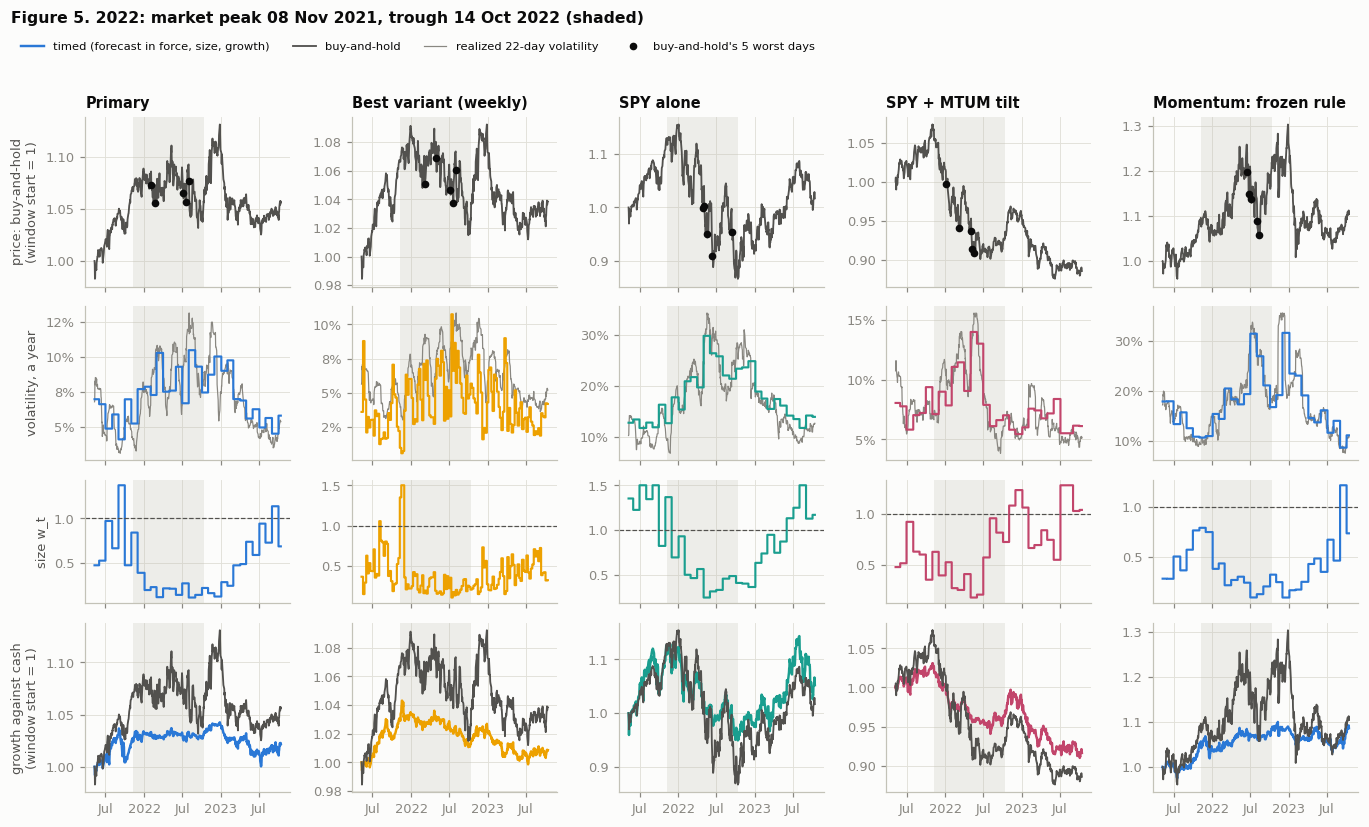

In [15]:
crisis_panel("2022", 5, [k for k in [("primary", "frozen"), ("best", "frozen"), ("spy", "frozen"), ("etf", "frozen"), ("mom", "frozen")] if ((Q["episode"] == "2022") & (Q["book"] == k[0]) & (Q["version"] == k[1])).any()])

In [16]:
crisis_table("2022")

run,Primary,Best variant (weekly),Fixed book,SPY alone,SPY + MTUM tilt,Momentum: B&SC,Market: B&SC,Momentum: frozen rule
"1. size, 6 months before",0.76,0.49,0.76,1.29,0.59,0.60,0.89,0.48
1. size at the peak,0.84,1.35,0.84,1.37,0.63,0.89,1.02,0.79
1. size on the 5 worst days,0.22,0.22,0.31,0.37,0.27,0.60,0.54,0.16
1. loss on them: timed,-1.6%,-1.4%,-2.0%,-7.2%,-2.1%,-11.0%,-10.5%,-2.9%
1. loss on them: buy-and-hold,-7.4%,-6.0%,-6.8%,-19.4%,-8.2%,-18.3%,-19.8%,-18.3%
1. share of the loss,0.22,0.24,0.30,0.37,0.26,0.60,0.53,0.16
2. fall: timed,+0.6%,-1.5%,-0.9%,-15.7%,-5.9%,+9.0%,-16.8%,+3.1%
2. fall: buy-and-hold,-0.2%,-2.9%,-2.2%,-23.0%,-12.7%,+12.4%,-26.0%,+12.4%
2. size in the fall,0.24,0.32,0.38,0.55,0.49,0.78,0.66,0.33
2. rebound: timed,-1.1%,-0.6%,-0.5%,+10.7%,-5.2%,-3.8%,+7.2%,-0.3%


**Reading.**

1. **Risk was cut early.** Volatility built up through the first half of 2022, so the monthly forecasts caught it.
   - SPY went from 1.29–1.37 (levered at the November 2021 peak) to 0.37 on its five worst days, and took 37% of the loss.
   - The primary held 0.22 and took 22%.
   - Over the fall, SPY timed lost 16% against 23%.
2. **The rebound was partly missed.** SPY gained +11% in the year after the trough, at a size of 0.88, against +17%. Over the whole window it grew +1.3% against −1.5%, a small win.
3. **The paper mixes hardly fell at all.**
   - The primary's buy-and-hold lost 0.2% from peak to trough. Momentum rose (+12% at size 1 over the fall), and the other factors offset the market's share, much as in 2000–2002.
   - Timing then had little to protect, and cost 3 points over the window (+1.6% against +4.4%).
   - The SPY + MTUM tilt lost less than buy-and-hold over the window (−10% against −15%).

## 7. The verdict

The plan's table, with each book's development column fixed in Entry 13 before the holdout was opened. A book's development is "wins" only if its own registered development test read "edge".

In [17]:
cols = ["name", "role", "development", "development_result", "statistic", "holdout_gain", "holdout_p", "holdout_reading", "holdout", "verdict"]
display(V[cols].set_index("name").style.format({"holdout_gain": "{:+.3f}", "holdout_p": "{:.3f}"}))

,role,development,development_result,statistic,holdout_gain,holdout_p,holdout_reading,holdout,verdict
name,,,,,,,,,
"Primary (screened book, M3)",the final test,fails,"Phase 7's primary test: +0.013, p 0.471, inconclusive (option (c), information: +0.214, p 0.059)",(c),+0.088,0.314,inconclusive,"flat, slightly negative or too short to tell",consistent with Cederburg et al.; report it
"Best variant (M0, downside vol, shrunk MV, weekly)",secondary,fails,"Phase 7's family: +0.234, raw p 0.089, inconclusive; Romano-Wolf p 0.43; deflated Sharpe 0.67",(c),-0.114,0.736,inconclusive,"flat, slightly negative or too short to tell",consistent with Cederburg et al.; report it
ETF track: SPY alone (M2),secondary,fails,"Phase 7's ETF track: +0.165, p 0.13, inconclusive",(a),-0.102,0.726,inconclusive,"flat, slightly negative or too short to tell",consistent with Cederburg et al.; report it
ETF track: SPY + MTUM tilt (M3),secondary,fails,"Phase 7's ETF track: +0.088, p 0.30, inconclusive (20 months)",(a),+0.015,0.467,inconclusive,"flat, slightly negative or too short to tell",consistent with Cederburg et al.; report it
"Phase 6's fixed book (M3, information)",information,wins,"Phases 6-7: +0.355, p 0.0002, edge, on an asset list chosen with the whole development sample",(a),+0.080,0.319,inconclusive,"flat, slightly negative or too short to tell",inconclusive: too short to tell; report both


**In plain language.**

- **The final test is inconclusive.**
  - Over 91 months, timing the diversified factor mix by its forecast variance raised its Sharpe ratio by **+0.09 a year** (p 0.31).
  - That is well inside the noise: the test could only have detected a gain of about 0.45.
  - On development it had not won either (+0.01 as registered; +0.21, p 0.06, under the holdout's scaling). So by the plan's table the result is **consistent with Cederburg et al. (2020)**: volatility management of a diversified portfolio does not reliably beat holding it, in real time and out of sample.
- **Nothing else rescues it:**
  - the family's best development variant lost 0.11;
  - the tradeable SPY version lost 0.10 after costs;
  - the SPY + MTUM tilt was flat;
  - the placebo failed;
  - the combination test added nothing.
- **Phase 6's strong development edge mostly faded.** The fixed book is information, because its asset list was chosen with the whole development sample. It gained +0.08 against +0.355 on development. The plan's table reads this as inconclusive, too short to tell, and both numbers are reported. The holdout's upper bound (+0.36) just reaches the development estimate, so an edge that large is now unlikely, though not ruled out.
- **No large failure either.** No book read "no meaningful edge". What timing reliably did was cut risk:
  - it halved the volatility and drawdowns of the factor mix, and cut SPY's drawdown from 24% to 15%;
  - in both crises it cut size before most of the worst days.

  It paid for that by holding too little: about half of buy-and-hold in a holdout more volatile than the history its scale was set on. In 2020 it missed most of the rebound.
- **What 92 months can and cannot say.** They cannot tell a modest edge from none: every Sharpe ratio here is known to about ±0.7, and the gain to about ±0.35. They can say that the large development gains (+0.2 to +0.36) did not show up out of sample.

**Labels.** Every paper result is an upper bound: paper BAB and profitability cannot be traded, and the paper books carry no costs. M3 was chosen by a 0.002 margin (Entry 5). Every reading here was decided by rules fixed before the holdout was opened, and none was re-tuned.